# CO3 Final Project: RF-DETR for Object Detection

## Group members
[names]

## Dataset
"traffic" v1 (2025-04-29) by Roboflow user nln
https://universe.roboflow.com/nln/traffic-yc409 (CC BY 4.0)
504 images (448x448), 5,405 boxes, 2 classes: car and bike.

## Task
Detect cars and bikes using a fine-tuned RF-DETR model, evaluated with
classification accuracy, precision, recall, and mAP.

Install and connect Drive

In [1]:
!pip install -q "rfdetr[train,loggers]" pycocotools reportlab

import os, glob, json, random, shutil, zipfile, time, pickle
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import drive, files

drive.mount("/content/drive")
WORK = "/content/drive/MyDrive/CO3"
os.makedirs(WORK + "/runs", exist_ok=True)
print("Saving everything in:", WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving everything in: /content/drive/MyDrive/CO3


Unzip your dataset

In [2]:
RAW = "/content/raw"

if not os.path.exists(RAW):
    zips = glob.glob(WORK + "/*.zip")
    if not zips:
        uploaded = files.upload()
        for name in uploaded:
            shutil.move("/content/" + name, WORK + "/" + name)
        zips = glob.glob(WORK + "/*.zip")
    os.makedirs(RAW, exist_ok=True)
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(RAW)

for p in sorted(glob.glob(RAW + "/**/_annotations.coco.json", recursive=True)):
    print(p)

/content/raw/train/_annotations.coco.json


Look at the raw dataset

In [4]:
raw_rows = []
for p in sorted(glob.glob(RAW + "/**/_annotations.coco.json", recursive=True)):
    coco = json.load(open(p))
    raw_rows.append((os.path.basename(os.path.dirname(p)), len(coco["images"]), len(coco["annotations"])))
    first_categories = coco["categories"]

print(pd.DataFrame(raw_rows, columns=["folder", "images", "boxes"]).to_string(index=False))
print()
for c in first_categories:
    print(c)

folder  images  boxes
 train     504   5405

{'id': 0, 'name': 'car', 'supercategory': 'none'}
{'id': 1, 'name': 'bike', 'supercategory': 'car'}
{'id': 2, 'name': 'car', 'supercategory': 'car'}


Preprocessing and splitting 70/15/15

In [3]:
DATASET = "/content/dataset"
SEED = 42

all_images = []
all_anns = defaultdict(list)
categories = None

for path in sorted(glob.glob(RAW + "/**/_annotations.coco.json", recursive=True)):
    folder = os.path.dirname(path)
    coco = json.load(open(path))
    if categories is None:
        categories = coco["categories"]
    local = {}
    for im in coco["images"]:
        full = os.path.join(folder, im["file_name"])
        if os.path.exists(full):
            local[im["id"]] = len(all_images)
            all_images.append({"src": full, "name": os.path.basename(im["file_name"]),
                               "width": im["width"], "height": im["height"]})
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        if a["image_id"] in local and w > 1 and h > 1:
            all_anns[local[a["image_id"]]].append({"category_id": a["category_id"], "bbox": [x, y, w, h]})

order = list(range(len(all_images)))
random.seed(SEED)
random.shuffle(order)
n = len(order)
cut1, cut2 = int(0.70 * n), int(0.85 * n)
split_ids = {"train": order[:cut1], "valid": order[cut1:cut2], "test": order[cut2:]}

if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

for split, ids in split_ids.items():
    os.makedirs(f"{DATASET}/{split}")
    images_out, anns_out = [], []
    for new_id, idx in enumerate(ids, start=1):
        im = all_images[idx]
        file_name = f"{idx:05d}_{im['name']}"
        shutil.copy(im["src"], f"{DATASET}/{split}/{file_name}")
        images_out.append({"id": new_id, "file_name": file_name, "width": im["width"], "height": im["height"]})
        for a in all_anns[idx]:
            anns_out.append({"id": len(anns_out) + 1, "image_id": new_id, "category_id": a["category_id"],
                             "bbox": a["bbox"], "area": a["bbox"][2] * a["bbox"][3],
                             "iscrowd": 0, "segmentation": []})
    json.dump({"info": {}, "licenses": [], "images": images_out, "annotations": anns_out,
               "categories": categories},
              open(f"{DATASET}/{split}/_annotations.coco.json", "w"))
    print(split, ":", len(images_out), "images,", len(anns_out), "boxes")

used_ids = sorted({a["category_id"] for anns in all_anns.values() for a in anns})
cat_names = {c["id"]: c["name"] for c in categories}
class_list = [cat_names[i] for i in used_ids]
print("Real classes:", dict(zip(used_ids, class_list)))

if not os.path.exists(WORK + "/dataset_preprocessed.zip"):
    shutil.make_archive(WORK + "/dataset_preprocessed", "zip", DATASET)
    print("Pre-processed dataset zipped to Drive")

train : 352 images, 3735 boxes
valid : 76 images, 841 boxes
test : 76 images, 829 boxes
Real classes: {1: 'bike', 2: 'car'}


Charts and a visual check

      train  valid  test
car    2337    522   501
bike   1398    319   328


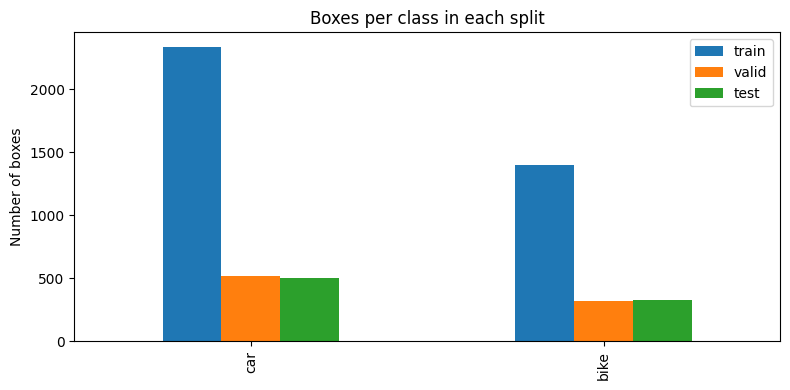

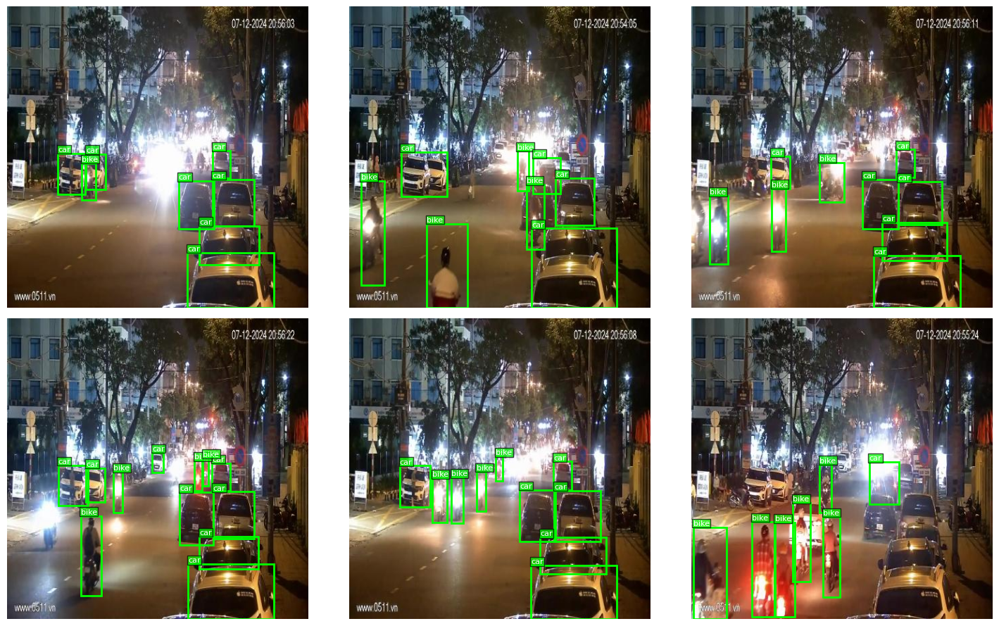

In [4]:
counts = {}
for split in ["train", "valid", "test"]:
    coco = json.load(open(f"{DATASET}/{split}/_annotations.coco.json"))
    counts[split] = Counter(cat_names[a["category_id"]] for a in coco["annotations"])
count_df = pd.DataFrame(counts).fillna(0).astype(int)
print(count_df)

count_df.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Number of boxes")
plt.title("Boxes per class in each split")
plt.tight_layout()
plt.savefig("/content/class_distribution.png", dpi=130)
plt.show()

def add_box(ax, box, color, text=None, style="-"):
    x1, y1, x2, y2 = box
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                   edgecolor=color, linewidth=2, linestyle=style))
    if text:
        ax.text(x1, max(y1 - 3, 8), text, color="white", fontsize=8,
                bbox=dict(facecolor=color, alpha=0.7, pad=1))

train_coco = json.load(open(f"{DATASET}/train/_annotations.coco.json"))
by_image = defaultdict(list)
for a in train_coco["annotations"]:
    by_image[a["image_id"]].append(a)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, im in zip(axes.flatten(), train_coco["images"][:6]):
    ax.imshow(Image.open(f"{DATASET}/train/{im['file_name']}").convert("RGB"))
    for a in by_image[im["id"]]:
        x, y, w, h = a["bbox"]
        add_box(ax, [x, y, x + w, y + h], "lime", cat_names[a["category_id"]])
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/annotation_check.png", dpi=110)
plt.show()

Training with checkpoints, early stopping, and resume

In [5]:
from rfdetr import RFDETRSmall

ModelClass = RFDETRSmall
EPOCHS = 30
BATCH = 4
ACCUM = 4
PATIENCE = 8

def find_checkpoint(folder, names):
    for name in names:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    return None

def train_run(name, lr):
    out = f"{WORK}/runs/{name}"
    os.makedirs(out, exist_ok=True)
    if os.path.exists(out + "/done.txt"):
        print(f"[{name}] already finished")
        return out
    settings = dict(dataset_dir=DATASET, epochs=EPOCHS, batch_size=BATCH, grad_accum_steps=ACCUM,
                    lr=lr, output_dir=out, early_stopping=True, early_stopping_patience=PATIENCE,
                    tensorboard=True)
    last = find_checkpoint(out, ["checkpoint.pth"])
    if last:
        settings["resume"] = last
        print(f"[{name}] resuming from {last}")
    else:
        print(f"[{name}] starting fresh")
    started = time.time()
    ModelClass().train(**settings)
    open(out + "/done.txt", "w").write(f"{time.time() - started:.0f}")
    return out

run_a = train_run("A_lr1e-4", 1e-4)
print(os.listdir(run_a))

[A_lr1e-4] starting fresh
[2026-10-12 04:38:50] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-12 04:38:50] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 04:38:50] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-12 04:38:51] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-12 04:38:53] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 04:38:53] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-12 04:38:55] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


...

[2026-10-12 05:09:23] [INFO] rf-detr - Best EMA metric improved to 0.6912 (epoch 26)
[2026-10-12 05:10:18] [INFO] rf-detr - Best EMA metric improved to 0.6919 (epoch 27)


INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.004 >= min_delta = 0.001. New best score: 0.695


[2026-10-12 05:11:05] [INFO] rf-detr - Best EMA metric improved to 0.6951 (epoch 28)


INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30` reached.


[2026-10-12 05:13:03] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.6951)
['training_config.json', 'events.out.tfevents.1791779941.bc06fa5349b5.5668.0', 'hparams.yaml', 'metrics.csv', 'checkpoint_best_ema.pth', 'last.ckpt', 'checkpoint_9.ckpt', 'checkpoint_19.ckpt', 'checkpoint_29.ckpt', 'checkpoint_best_total.pth', 'last_ema.pth', 'done.txt']


TensorBoard

In [6]:
%load_ext tensorboard
%tensorboard --logdir /content/drive/MyDrive/CO3/runs

<IPython.core.display.Javascript object>

Hyperparameter experiment

In [7]:
run_b = train_run("B_lr5e-5", 5e-5)
print(os.listdir(run_b))

[B_lr5e-5] starting fresh
[2026-10-12 05:15:34] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-12 05:15:34] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 05:15:34] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-12 05:15:35] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-12 05:15:37] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 05:15:37] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-12 05:15:39] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


...

[2026-10-12 05:43:21] [INFO] rf-detr - Best EMA metric improved to 0.6912 (epoch 23)


INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.002 >= min_delta = 0.001. New best score: 0.693


[2026-10-12 05:44:48] [INFO] rf-detr - Best EMA metric improved to 0.6932 (epoch 24)
[2026-10-12 05:48:50] [INFO] rf-detr - Best EMA metric improved to 0.6940 (epoch 27)
[2026-10-12 05:50:06] [INFO] rf-detr - Best EMA metric improved to 0.6942 (epoch 28)


INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30` reached.


[2026-10-12 05:53:23] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.6942)
['training_config.json', 'events.out.tfevents.1791782141.bc06fa5349b5.5668.1', 'hparams.yaml', 'metrics.csv', 'checkpoint_best_ema.pth', 'last.ckpt', 'checkpoint_9.ckpt', 'checkpoint_19.ckpt', 'checkpoint_29.ckpt', 'checkpoint_best_total.pth', 'last_ema.pth', 'done.txt']


Evaluation tools

In [8]:
from scipy.optimize import linear_sum_assignment
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

CONF = 0.5
IOU_THR = 0.5
ID_OFFSET = 0

test_dir = DATASET + "/test"
test_json = test_dir + "/_annotations.coco.json"
test_coco = json.load(open(test_json))
class_index = {cid: i for i, cid in enumerate(used_ids)}
K = len(used_ids)

gt_by_img = defaultdict(list)
for a in test_coco["annotations"]:
    x, y, w, h = a["bbox"]
    gt_by_img[a["image_id"]].append((a["category_id"], [x, y, x + w, y + h]))

def box_iou(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return inter / np.maximum(union, 1e-9)

def match_image(preds, gts):
    if not preds or not gts:
        return [], list(range(len(preds))), list(range(len(gts)))
    iou = box_iou([p[2] for p in preds], [g[1] for g in gts])
    rows, cols = linear_sum_assignment(-iou)
    pairs = [(int(r), int(c)) for r, c in zip(rows, cols) if iou[r, c] >= IOU_THR]
    used_p = {p for p, _ in pairs}
    used_g = {g for _, g in pairs}
    extra = [i for i in range(len(preds)) if i not in used_p]
    missed = [i for i in range(len(gts)) if i not in used_g]
    return pairs, extra, missed

def gt_area(g):
    x1, y1, x2, y2 = g[1]
    return (x2 - x1) * (y2 - y1)

def load_best(out):
    best = find_checkpoint(out, ["checkpoint_best_total.pth", "checkpoint_best_ema.pth",
                                 "checkpoint_best_regular.pth"])
    if best is None:
        raise FileNotFoundError("No best checkpoint in " + out + ". Files: " + str(os.listdir(out)))
    return ModelClass(pretrain_weights=best)

def run_predictions(model):
    result = {}
    for im in test_coco["images"]:
        pil = Image.open(os.path.join(test_dir, im["file_name"])).convert("RGB")
        det = model.predict(pil, threshold=0.01)
        if len(det) == 0:
            result[im["id"]] = []
        else:
            result[im["id"]] = [(int(c), float(s), [float(v) for v in b])
                                for c, s, b in zip(det.class_id, det.confidence, det.xyxy)]
    return result

def get_predictions(name):
    out = f"{WORK}/runs/{name}"
    cache = out + "/test_predictions.pkl"
    if os.path.exists(cache):
        return pickle.load(open(cache, "rb"))
    preds = run_predictions(load_best(out))
    pickle.dump(preds, open(cache, "wb"))
    return preds

def score_predictions(all_preds):
    cm = np.zeros((K + 1, K + 1), dtype=int)
    tp = fp = fn = matched = correct = unknown = 0
    image_errors = {}
    gt_hits = []
    for im in test_coco["images"]:
        gts = gt_by_img.get(im["id"], [])
        raw = [(c + ID_OFFSET, s, b) for c, s, b in all_preds[im["id"]] if s >= CONF]
        preds = [p for p in raw if p[0] in class_index]
        unknown += len(raw) - len(preds)
        pairs, extra, missed = match_image(preds, gts)
        err = 0
        for pi, gi in pairs:
            matched += 1
            pc, gc = class_index[preds[pi][0]], class_index[gts[gi][0]]
            cm[pc, gc] += 1
            if pc == gc:
                tp += 1
                correct += 1
                gt_hits.append((gt_area(gts[gi]), 1))
            else:
                fp += 1
                fn += 1
                err += 2
                gt_hits.append((gt_area(gts[gi]), 0))
        for pi in extra:
            fp += 1
            err += 1
            cm[class_index[preds[pi][0]], K] += 1
        for gi in missed:
            fn += 1
            err += 1
            cm[K, class_index[gts[gi][0]]] += 1
            gt_hits.append((gt_area(gts[gi]), 0))
        image_errors[im["id"]] = err
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {"tp": tp, "fp": fp, "fn": fn, "cm": cm, "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / max(precision + recall, 1e-9),
            "class_acc": correct / max(matched, 1), "unknown": unknown,
            "image_errors": image_errors, "gt_hits": gt_hits}

coco_gt = COCO(test_json)

def coco_map(all_preds):
    results = []
    for img_id, preds in all_preds.items():
        for c, s, b in preds:
            results.append({"image_id": img_id, "category_id": c + ID_OFFSET,
                            "bbox": [b[0], b[1], b[2] - b[0], b[3] - b[1]], "score": s})
    if not results:
        return {"map5095": 0.0, "map50": 0.0}
    evaluator = COCOeval(coco_gt, coco_gt.loadRes(results), "bbox")
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()
    return {"map5095": float(evaluator.stats[0]), "map50": float(evaluator.stats[1])}

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Results

In [9]:
RUNS = ["A_lr1e-4", "B_lr5e-5"]
store = {}
rows = []

for name in RUNS:
    print("=" * 20, name, "=" * 20)
    preds = get_predictions(name)
    s = score_predictions(preds)
    m = coco_map(preds)
    store[name] = (preds, s, m)
    seconds = open(f"{WORK}/runs/{name}/done.txt").read() if os.path.exists(f"{WORK}/runs/{name}/done.txt") else "n/a"
    rows.append({"Run": name, "Classification accuracy": round(s["class_acc"], 4),
                 "Precision": round(s["precision"], 4), "Recall": round(s["recall"], 4),
                 "F1": round(s["f1"], 4), "mAP@0.5": round(m["map50"], 4),
                 "mAP@0.5:0.95": round(m["map5095"], 4), "TP": s["tp"], "FP": s["fp"], "FN": s["fn"],
                 "Unknown-class predictions": s["unknown"], "Last session train time (s)": seconds})

comparison = pd.DataFrame(rows)
comparison.to_csv(WORK + "/results_comparison.csv", index=False)
print()
print(comparison.to_string(index=False))

best_name = comparison.sort_values("mAP@0.5:0.95", ascending=False).iloc[0]["Run"]
print("\nBest run by mAP@0.5:0.95:", best_name)

[2026-10-12 05:54:42] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 05:54:42] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


==================== A_lr1e-4 ====================


[2026-10-12 05:54:44] [WARNING] rf-detr - Checkpoint has 2 classes but model is configured for 90. Using checkpoint class count (2). Pass num_classes=2 to suppress this warning.
[2026-10-12 05:54:44] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*


[2026-10-12 05:54:49] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 05:54:49] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


DONE (t=0.57s).
Accumulating evaluation results...
DONE (t=0.06s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.029
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.019
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.016
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.005
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.044
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.293
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.297
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.295
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= lar

[2026-10-12 05:54:50] [WARNING] rf-detr - Checkpoint has 2 classes but model is configured for 90. Using checkpoint class count (2). Pass num_classes=2 to suppress this warning.
[2026-10-12 05:54:50] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.65s).
Accumulating evaluation results...
DONE (t=0.07s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.021
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.035
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.022
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.029
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.126
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.005
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.053
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.339
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

Confusion matrices

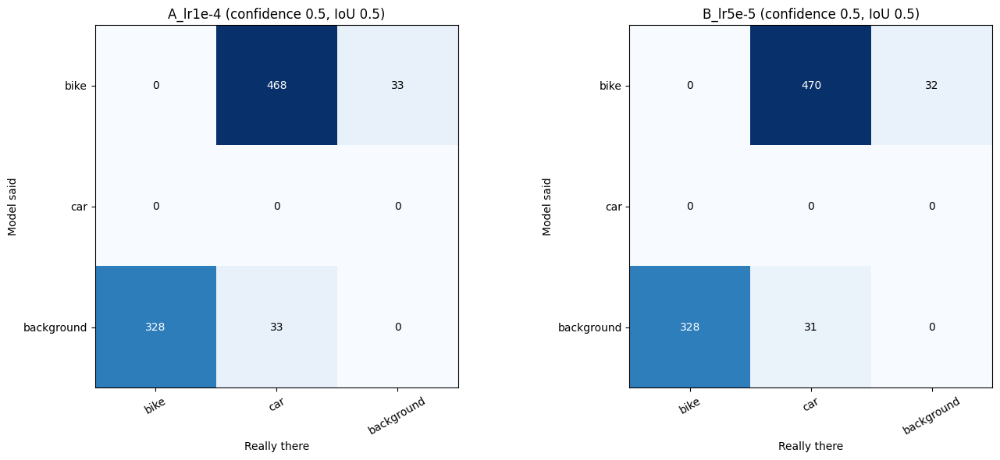

In [10]:
labels = class_list + ["background"]
fig, axes = plt.subplots(1, len(RUNS), figsize=(7 * len(RUNS), 6))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, RUNS):
    cm = store[name][1]["cm"]
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(K + 1))
    ax.set_xticklabels(labels, rotation=30)
    ax.set_yticks(range(K + 1))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Really there")
    ax.set_ylabel("Model said")
    ax.set_title(f"{name} (confidence {CONF}, IoU {IOU_THR})")
    for i in range(K + 1):
        for j in range(K + 1):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("/content/confusion_matrices.png", dpi=130)
plt.show()

Visualize predictions on test pictures

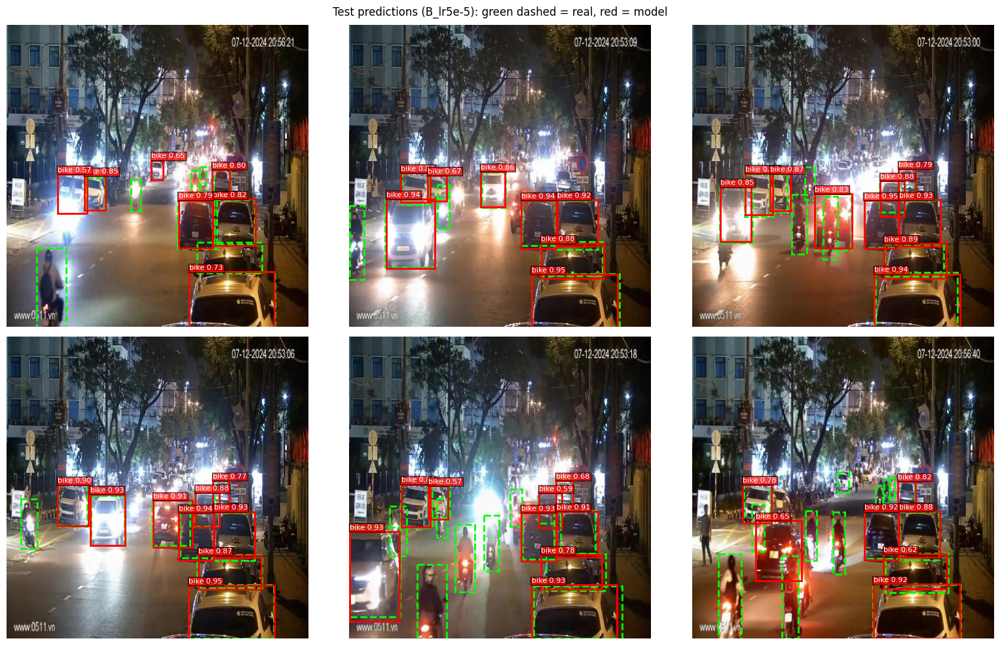

In [11]:
best_preds = store[best_name][0]
random.seed(1)
chosen = random.sample(test_coco["images"], min(6, len(test_coco["images"])))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, im in zip(axes.flatten(), chosen):
    ax.imshow(Image.open(os.path.join(test_dir, im["file_name"])).convert("RGB"))
    for g in gt_by_img.get(im["id"], []):
        add_box(ax, g[1], "lime", None, "--")
    for c, s, b in best_preds[im["id"]]:
        if s >= CONF and (c + ID_OFFSET) in class_index:
            add_box(ax, b, "red", f"{cat_names[c + ID_OFFSET]} {s:.2f}")
    ax.axis("off")
plt.suptitle(f"Test predictions ({best_name}): green dashed = real, red = model")
plt.tight_layout()
plt.savefig("/content/predictions.png", dpi=110)
plt.show()

Error analysis

class  precision  recall
 bike        0.0     0.0
  car        0.0     0.0

            object size  real boxes  found correctly
    small (under 32x32)         156              0.0
medium (32x32 to 96x96)         602              0.0
   large (96x96 and up)          71              0.0


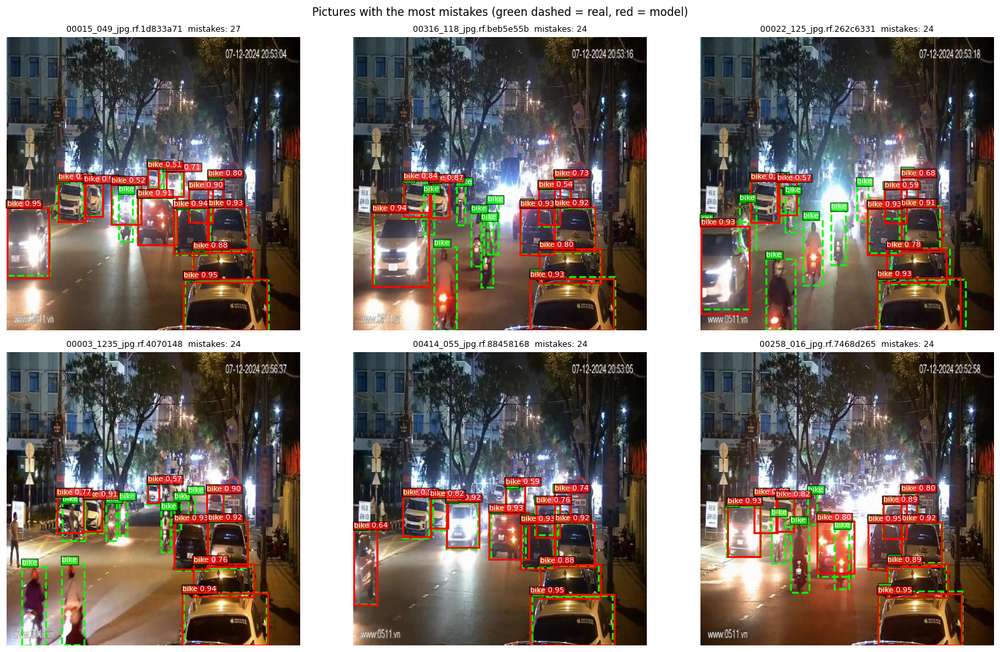

In [12]:
s = store[best_name][1]
cm = s["cm"]
per_class = []
for i, cname in enumerate(class_list):
    per_class.append((cname, round(cm[i, i] / max(cm[i, :].sum(), 1), 3),
                      round(cm[i, i] / max(cm[:, i].sum(), 1), 3)))
print(pd.DataFrame(per_class, columns=["class", "precision", "recall"]).to_string(index=False))

areas = np.array([a for a, _ in s["gt_hits"]])
hits = np.array([h for _, h in s["gt_hits"]])
bins = [("small (under 32x32)", areas < 32 * 32),
        ("medium (32x32 to 96x96)", (areas >= 32 * 32) & (areas < 96 * 96)),
        ("large (96x96 and up)", areas >= 96 * 96)]
size_rows = []
for label, mask in bins:
    size_rows.append((label, int(mask.sum()), round(float(hits[mask].mean()), 3) if mask.sum() else "n/a"))
size_df = pd.DataFrame(size_rows, columns=["object size", "real boxes", "found correctly"])
print()
print(size_df.to_string(index=False))

worst = sorted(s["image_errors"].items(), key=lambda kv: -kv[1])[:6]
id_to_image = {im["id"]: im for im in test_coco["images"]}
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (img_id, err) in zip(axes.flatten(), worst):
    im = id_to_image[img_id]
    ax.imshow(Image.open(os.path.join(test_dir, im["file_name"])).convert("RGB"))
    for g in gt_by_img.get(img_id, []):
        add_box(ax, g[1], "lime", cat_names[g[0]], "--")
    for c, sc, b in best_preds[img_id]:
        if sc >= CONF and (c + ID_OFFSET) in class_index:
            add_box(ax, b, "red", f"{cat_names[c + ID_OFFSET]} {sc:.2f}")
    ax.set_title(f"{im['file_name'][:25]}  mistakes: {err}", fontsize=9)
    ax.axis("off")
plt.suptitle("Pictures with the most mistakes (green dashed = real, red = model)")
plt.tight_layout()
plt.savefig("/content/worst_cases.png", dpi=110)
plt.show()